# **SEMESTER 1 LAB PRACTICAL 9**<br>Stereo Vision for Depth Estimation

## Setup and parameters

Import required libraries and plotting setup for interactive stereo vision. 

The parameters include:
- Baseline (distance between LEFT and RIGHT camera positions)
- Approximate focal length in pixels.


In [1]:
# ============================================================
# COMPUTER VISION PRACTICAL
# Stereo Vision for Depth Estimation Using One Laptop Camera
# ============================================================

# Requires ipympl for interactive Matplotlib events.
%matplotlib widget

import cv2
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display


# ============================================================
# PARAMETERS
# ============================================================

# Baseline: distance between LEFT and RIGHT camera positions
# 10 cm = 0.10 m
BASELINE = 0.10

# Approximate focal length in pixels.
# Replace this with the calibrated focal length if available.
FOCAL_LENGTH = 670.0


# ============================================================


## Step 1: CAPTURE LEFT AND RIGHT IMAGES

This step covers capture left and right images in the stereo depth-estimation workflow.


In [2]:
# STEP 1: CAPTURE LEFT AND RIGHT IMAGES
# ============================================================

print("==============================================")
print("     STEREO VISION DEPTH ESTIMATION")
print("==============================================")
print()
print("Instructions:")
print("1. Position the laptop at the LEFT position.")
print("2. Press L to capture the LEFT image.")
print("3. Move the laptop 6.5 cm horizontally RIGHT.")
print("4. Do NOT rotate or tilt the laptop.")
print("5. Press R to capture the RIGHT image.")
print("6. Press Q when both images have been captured.")
print()

cap = cv2.VideoCapture(0)

if not cap.isOpened():
    print("ERROR: Camera could not be opened.")
    exit()

left_captured = False
right_captured = False

while True:

    ret, frame = cap.read()

    if not ret:
        print("ERROR: Could not read camera frame.")
        break

    # Display instructions on camera window
    display_frame = frame.copy()

    cv2.putText(
        display_frame,
        "L = Left | R = Right | Q = Continue",
        (20, 30),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.7,
        (0, 255, 0),
        2
    )

    cv2.imshow("Stereo Image Capture", display_frame)

    key = cv2.waitKey(1) & 0xFF

    # Capture LEFT image
    if key == ord('l'):

        cv2.imwrite("left.jpg", frame)

        left_captured = True

        print()
        print("LEFT image captured.")
        print("Now move the laptop 6.5 cm horizontally RIGHT.")
        print("Keep the camera at the same height and orientation.")
        print("Then press R.")

    # Capture RIGHT image
    elif key == ord('r'):

        if not left_captured:
            print("Capture the LEFT image first!")

        else:
            cv2.imwrite("right.jpg", frame)

            right_captured = True

            print()
            print("RIGHT image captured.")

    # Continue
    elif key == ord('q'):
        break
        # if left_captured and right_captured:
        #     break

        # else:
        #     print("Please capture BOTH left and right images first.")


cap.release()
cv2.destroyAllWindows()


# ============================================================


     STEREO VISION DEPTH ESTIMATION

Instructions:
1. Position the laptop at the LEFT position.
2. Press L to capture the LEFT image.
3. Move the laptop 6.5 cm horizontally RIGHT.
4. Do NOT rotate or tilt the laptop.
5. Press R to capture the RIGHT image.
6. Press Q when both images have been captured.



## Step 2: LOAD THE STEREO IMAGES

This step covers load the stereo images in the stereo depth-estimation workflow.


In [3]:
# STEP 2: LOAD THE STEREO IMAGES
# ============================================================

left = cv2.imread("left.jpg")
right = cv2.imread("right.jpg")

if left is None or right is None:
    print("ERROR: Images could not be loaded.")
    exit()

print()
print("Stereo images successfully loaded.")


# ============================================================



Stereo images successfully loaded.


## Step 3: CHECK IMAGE DIMENSIONS

This step covers check image dimensions in the stereo depth-estimation workflow.


In [4]:
# STEP 3: CHECK IMAGE DIMENSIONS
# ============================================================

if left.shape != right.shape:

    print("Image sizes are different.")
    print("Resizing RIGHT image...")

    right = cv2.resize(
        right,
        (left.shape[1], left.shape[0])
    )


# ============================================================


## Step 4: DISPLAY LEFT AND RIGHT IMAGES

This step covers display left and right images in the stereo depth-estimation workflow.


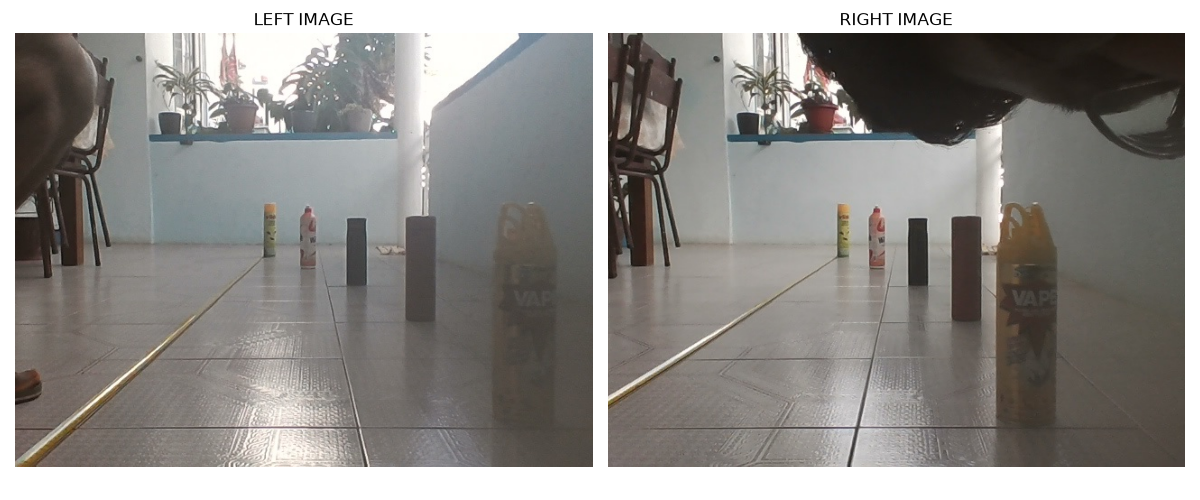

In [5]:
# STEP 4: DISPLAY LEFT AND RIGHT IMAGES
# ============================================================

left_rgb = cv2.cvtColor(left, cv2.COLOR_BGR2RGB)
right_rgb = cv2.cvtColor(right, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(left_rgb)
plt.title("LEFT IMAGE")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(right_rgb)
plt.title("RIGHT IMAGE")
plt.axis("off")

plt.tight_layout()
plt.show()


# ============================================================


## Step 5: CONVERT IMAGES TO GRAYSCALE

This step covers convert images to grayscale in the stereo depth-estimation workflow.


In [6]:
# STEP 5: CONVERT IMAGES TO GRAYSCALE
# ============================================================

left_gray = cv2.cvtColor(
    left,
    cv2.COLOR_BGR2GRAY
)

right_gray = cv2.cvtColor(
    right,
    cv2.COLOR_BGR2GRAY
)


# ============================================================


## Step 6: CREATE STEREO SGBM MATCHER

Number of disparities MUST be divisible by 16.


In [7]:
# STEP 6: CREATE STEREO SGBM MATCHER
# ============================================================

# Number of disparities MUST be divisible by 16.
num_disparities = 16 * 8       # 128 disparities

block_size = 5

stereo = cv2.StereoSGBM_create(

    minDisparity=0,

    numDisparities=num_disparities,

    blockSize=block_size,

    P1=8 * block_size ** 2,

    P2=32 * block_size ** 2,

    uniquenessRatio=10,

    speckleWindowSize=100,

    speckleRange=2,

    disp12MaxDiff=1,

    mode=cv2.STEREO_SGBM_MODE_SGBM_3WAY
)


# ============================================================


## Step 7: CALCULATE DISPARITY

This step covers calculate disparity in the stereo depth-estimation workflow.


In [8]:
# STEP 7: CALCULATE DISPARITY
# ============================================================

print()
print("Calculating disparity map...")

disparity = stereo.compute(
    left_gray,
    right_gray
).astype(np.float32) / 16.0


# ============================================================



Calculating disparity map...


## Step 8: DISPLAY DISPARITY MAP

This step covers display disparity map in the stereo depth-estimation workflow.


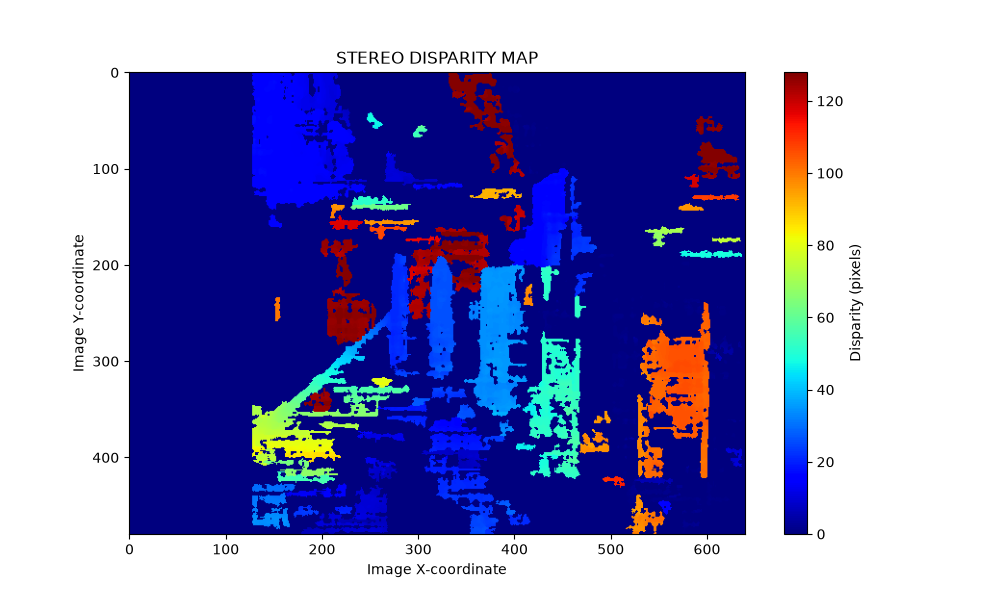

In [9]:
# STEP 8: DISPLAY DISPARITY MAP
# ============================================================

plt.figure(figsize=(10, 6))

plt.imshow(
    disparity,
    cmap="jet",
    vmin=0,
    vmax=num_disparities
)

plt.colorbar(
    label="Disparity (pixels)"
)

plt.title("STEREO DISPARITY MAP")

plt.xlabel("Image X-coordinate")
plt.ylabel("Image Y-coordinate")

plt.show()


# ============================================================


## Step 9: CALCULATE DEPTH MAP

Stereo depth equation:
$$Z = \frac{f \times B}{d}$$

where:
- $Z$ = depth (metres)
- $f$ = focal length (pixels)
- $B$ = baseline (metres)
- $d$ = disparity (pixels)




In [10]:
# STEP 9: CALCULATE DEPTH MAP
# ============================================================

# Stereo depth equation:
#
#             f × B
#       Z = ---------
#               d
#
# Z = depth (metres)
# f = focal length (pixels)
# B = baseline (metres)
# d = disparity (pixels)


depth = np.full(
    disparity.shape,
    np.nan,
    dtype=np.float32
)

# Only positive disparities are valid
valid = disparity > 0

depth[valid] = (
    FOCAL_LENGTH * BASELINE
) / disparity[valid]


# ============================================================


## Step 10: LIMIT DEPTH FOR VISUALISATION

Ignore extremely large distances when displaying the map


In [11]:
# STEP 10: LIMIT DEPTH FOR VISUALISATION
# ============================================================

# Ignore extremely large distances when displaying the map
max_depth = 5.0

depth_display = depth.copy()

depth_display[
    depth_display > max_depth
] = np.nan


# ============================================================


## Step 11: DISPLAY DEPTH MAP

This step covers display depth map in the stereo depth-estimation workflow.


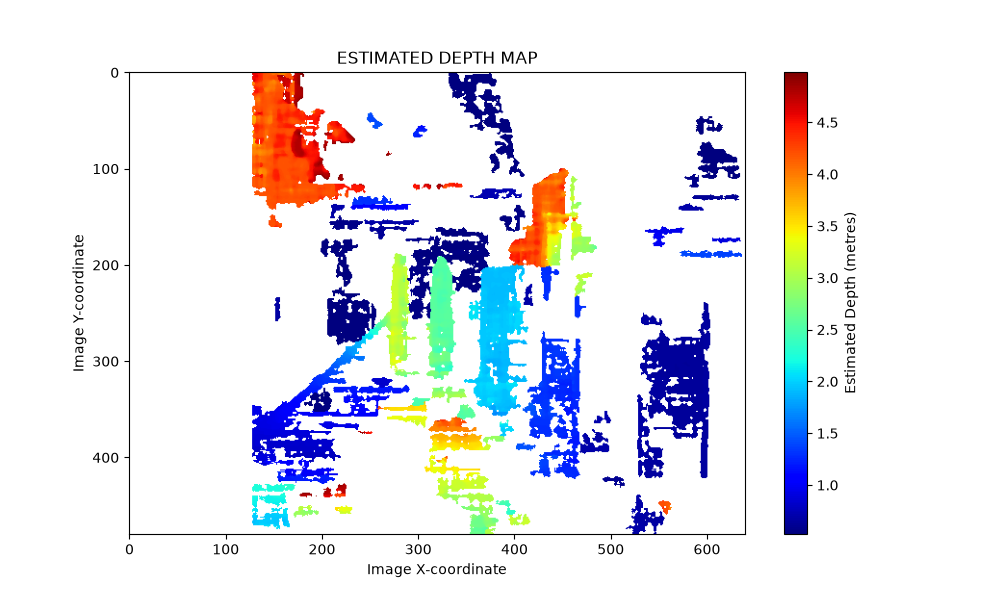

In [12]:
# STEP 11: DISPLAY DEPTH MAP
# ============================================================

plt.figure(figsize=(10, 6))

depth_image = plt.imshow(
    depth_display,
    cmap="jet"
)

plt.colorbar(
    depth_image,
    label="Estimated Depth (metres)"
)

plt.title("ESTIMATED DEPTH MAP")

plt.xlabel("Image X-coordinate")
plt.ylabel("Image Y-coordinate")

plt.show()


# ============================================================


## Step 12: INTERACTIVE DEPTH MEASUREMENT

This step covers interactive depth measurement in the stereo depth-estimation workflow.



INTERACTIVE DEPTH MEASUREMENT

Click on an object in the disparity map.
The program will estimate its distance.



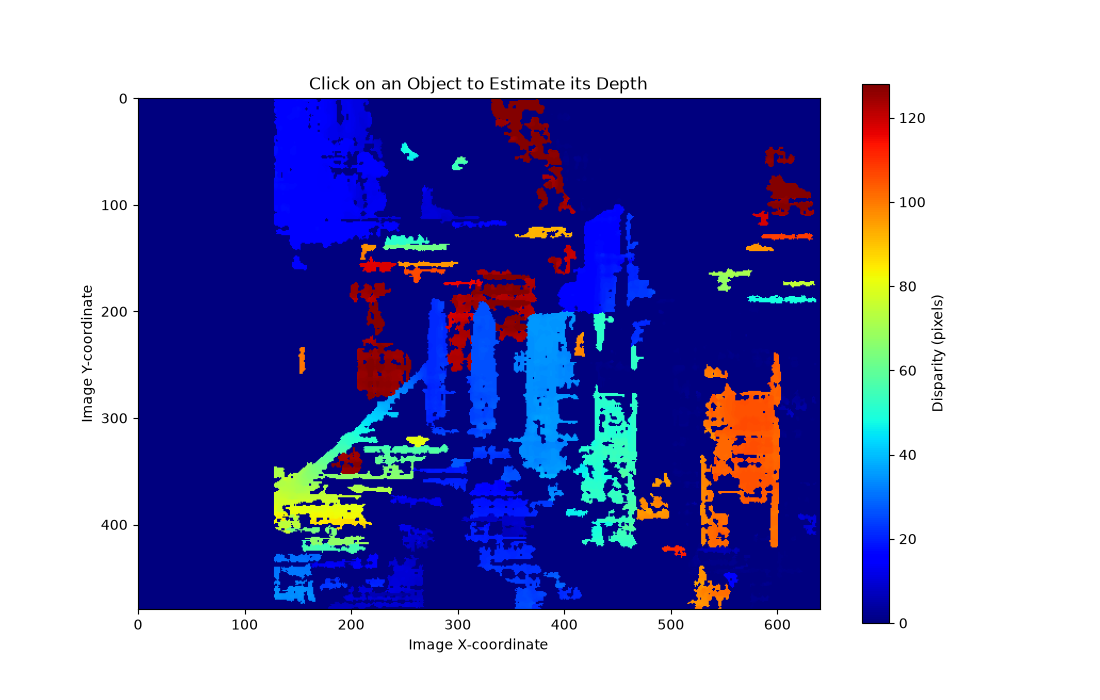

Output()

In [13]:
# STEP 12: INTERACTIVE DEPTH MEASUREMENT
# ============================================================

print()
print("==============================================")
print("INTERACTIVE DEPTH MEASUREMENT")
print("==============================================")
print()
print("Click on an object in the disparity map.")
print("The program will estimate its distance.")
print()


fig, ax = plt.subplots(figsize=(11, 7))

image = ax.imshow(
    disparity,
    cmap="jet",
    vmin=0,
    vmax=num_disparities
)

plt.colorbar(
    image,
    ax=ax,
    label="Disparity (pixels)"
)

ax.set_title(
    "Click on an Object to Estimate its Depth"
)

ax.set_xlabel("Image X-coordinate")
ax.set_ylabel("Image Y-coordinate")

click_output = widgets.Output()

# ============================================================
# FUNCTION EXECUTED WHEN USER CLICKS
# ============================================================

def onclick(event):

    # Ignore clicks outside image
    if event.xdata is None or event.ydata is None:
        return

    x = int(event.xdata)
    y = int(event.ydata)

    # Check image boundaries
    if (
        x < 0 or
        y < 0 or
        x >= disparity.shape[1] or
        y >= disparity.shape[0]
    ):
        return

    d = disparity[y, x]
    if d > 0:
        Z = (
            FOCAL_LENGTH *
            BASELINE
        ) / d

    with click_output:
        print()
        print("----------------------------------")
        print("Selected pixel:")
        print("X =", x)
        print("Y =", y)

        if d > 0:
            print(
                "Disparity =",
                round(float(d), 2),
                "pixels"
            )
            print(
                "Estimated Depth =",
                round(float(Z), 2),
                "metres"
            )
        else:
            print("Invalid disparity at this point.")
            print(
                "Try clicking on a textured "
                "part of the object."
            )

    if d > 0:
        # Mark selected point
        ax.plot(
            x,
            y,
            marker="x",
            markersize=10
        )

        # Display depth value
        ax.text(
            x + 10,
            y,
            f"{Z:.2f} m",
            fontsize=10,
            bbox=dict(
                boxstyle="round",
                alpha=0.7
            )
        )

        fig.canvas.draw()

# Connect mouse click event
fig.canvas.mpl_connect(
    "button_press_event",
    onclick
)

plt.show()
display(click_output)


# ============================================================


## Step 13: EXAMPLE DEPTH CALCULATIONS

This step covers example depth calculations in the stereo depth-estimation workflow.


In [14]:
# STEP 13: EXAMPLE DEPTH CALCULATIONS
# ============================================================

print()
print("==============================================")
print("EXAMPLE DEPTH CALCULATIONS")
print("==============================================")

image_height, image_width = disparity.shape

# Five sample (x, y) pixel coordinates across the image centerline.
example_points = [
    (565, 299), # (image_width // 6, image_height // 2),
    (442, 313), # (image_width // 3, image_height // 2),
    (382, 253), # (image_width // 2, image_height // 2),
    (323, 236),# (2 * image_width // 3, image_height // 2),
    (280, 235) # (5 * image_width // 6, image_height // 2)
]

for x, y in example_points:

    if x < 0 or y < 0 or x >= image_width or y >= image_height:
        print(f"Point (x={x}, y={y}) is outside the image.")
        continue

    d = disparity[y, x]

    if d > 0:
        Z = depth[y, x]
        print(f"Point (x={x}, y={y}) -> Depth: {Z:.2f} m")
    else:
        print(f"Point (x={x}, y={y}) -> Invalid disparity; no depth available.")


# ============================================================



EXAMPLE DEPTH CALCULATIONS
Point (x=565, y=299) -> Depth: 0.64 m
Point (x=442, y=313) -> Depth: 1.33 m
Point (x=382, y=253) -> Depth: 2.00 m
Point (x=323, y=236) -> Depth: 2.47 m
Point (x=280, y=235) -> Depth: 3.05 m


## Step 14: SAVE RESULTS

Normalize disparity for saving as image


In [15]:
# STEP 14: SAVE RESULTS
# ============================================================

# Normalize disparity for saving as image
valid_disp = np.maximum(
    disparity,
    0
)

disp_normalized = cv2.normalize(
    valid_disp,
    None,
    0,
    255,
    cv2.NORM_MINMAX
)

disp_normalized = np.uint8(
    disp_normalized
)

cv2.imwrite(
    "disparity_map.jpg",
    disp_normalized
)

print()
print("Disparity map saved as:")
print("disparity_map.jpg")


# ============================================================
# END OF PROGRAM
# ============================================================

print()
print("==============================================")
print("EXPERIMENT COMPLETED")
print("==============================================")

print()
print("Parameters used:")

print(
    "Baseline =",
    BASELINE,
    "m"
)

print(
    "Focal length =",
    FOCAL_LENGTH,
    "pixels"
)

print()
print(
    "NOTE: The calculated depth is approximate "
    "because the focal length has been assumed."
)

print(
    "For accurate measurements, perform camera "
    "calibration and stereo rectification."
)



Disparity map saved as:
disparity_map.jpg

EXPERIMENT COMPLETED

Parameters used:
Baseline = 0.1 m
Focal length = 670.0 pixels

NOTE: The calculated depth is approximate because the focal length has been assumed.
For accurate measurements, perform camera calibration and stereo rectification.


## Experimental Results
From the camera calibration results of the previous practical,
$$
\text{Camera matrix, } K = \begin{bmatrix}
    f_x & 0 & c_x \\
    0 & f_y & c_y \\
    0 & 0 & 1
\end{bmatrix} = \begin{bmatrix}
    666.3155937 & 0 & 302.4419719 \\
    0 & 674.02531069 & 159.53081679 \\
    0 & 0 & 1
\end{bmatrix}
$$
We can find the focal length using:
$$
\text{Focal length, } f = \frac{f_x + f_y}{2}
$$
$$
f = \frac{666.3155937 + 674.02531069}{2} = 670.2 \text{ px}
$$
Here are the results of depth estimation using different baselines:
### B = 0.030 m
| Object | Actual Distance (m) | Disparity, $d$ (pixels) | Estimated Depth (m) | Absolute Error (m) |
| --- | --- | --- | --- | --- |
| A | 0.60 | 29.00 | 0.69 | 0.09 |
| B | 1.20 | 12.62 | 1.59 | 0.39 |
| C | 1.80 | 8.12 | 2.47 | 0.67 |
| D | 2.40 | 6.00 | 3.35 | 0.95 |
| E | 3.00 | 4.38 | 4.59 | 1.59 |

###  B = 0.065 m
| Object | Actual Distance (m) | Disparity, $d$ (pixels) | Estimated Depth (m) | Absolute Error (m) |
| --- | --- | --- | --- | --- |
| A | 0.60 | 67.69 | 0.64 | 0.04 |
| B | 1.20 | 32.75 | 1.33 | 0.13 |
| C | 1.80 | 21.00 | 2.07 | 0.27 |
| D | 2.40 | 15.75 | 2.77 | 0.37 |
| E | 3.00 | 13.31 | 3.27 | 0.27 |
### B = 0.100 m
| Object | Actual Distance (m) | Disparity, $d$ (pixels) | Estimated Depth (m) | Absolute Error (m) |
| --- | --- | --- | --- | --- |
| A | 0.60 | 105.25 | 0.64 | 0.04 |
| B | 1.20 | 50.69 | 1.32 | 0.12 |
| C | 1.80 | 34.00 | 1.97 | 0.17 |
| D | 2.40 | 26.44 | 2.53 | 0.13 |
| E | 3.00 | 21.81 | 3.07 | 0.07 |

## Questions
1. **What is stereo disparity?**
> Stereo disparity is the difference in image position of the same point in the left and right images. After rectification, it is usually measured as the horizontal pixel difference, `d = x_L - x_R`.

2. **Why do nearby objects have greater disparity than distant objects?**
> A nearby object shifts more between the two camera views than a distant object. For a rectified stereo pair, disparity is approximately `d = fB/Z`, where `f` is focal length, `B` is baseline, and `Z` is depth.

3. **What is meant by the baseline of a stereo system?**
> The baseline is the distance between the optical centers of the left and right cameras.

4. **What happens to estimated depth when disparity increases?**
> Estimated depth decreases because depth is inversely proportional to disparity: `Z = fB/d` for calibrated, rectified cameras.

5. **Why should the left and right cameras ideally have parallel optical axes?**
> Parallel optical axes make corresponding points appear at approximately the same vertical position, so disparity is mainly horizontal and matching is simpler. If the axes are not parallel, calibration and rectification can compensate for the difference.

6. **Why is stereo rectification necessary?**
> Rectification transforms the images so corresponding points lie on the same horizontal scanline. This reduces matching to a horizontal search and simplifies disparity calculation.

7. **Why do textureless regions produce poor disparity estimates?**
> Textureless regions lack distinctive features, so many locations look alike and the algorithm cannot reliably identify corresponding points.

8. **What happens if the baseline is increased?**
> For the same focal length and object, disparity increases, which can improve depth sensitivity. However, a larger baseline can also increase occlusions and make matching harder.

9. **Why are some pixels in the disparity map invalid?**
> Some pixels have no reliable correspondence because they are occluded, outside the cameras' overlapping views, textureless, or rejected by the matcher as inconsistent or low-confidence.

10. **How does camera calibration improve the accuracy of depth estimation?**
> Calibration estimates focal length, lens distortion, and the cameras' relative positions and orientations. These parameters enable accurate rectification and conversion of disparity into depth.

## THE END
Thank you for watching!